In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("../data/raw/positive_rep_virus_dataset.csv")

In [3]:
df

,taxid,virus_name,sDBM_pos,sDBM,sDBM_sim_gap,ori_seq,ori_align_score,iteration_name,rep_amino_acid_seq
0,59817,Faba bean necrotic yellows virus,"(63, 71)",GAHFEKRRG,33.0,TAGTATTAC,138.5,FBNYY_iter1_V_A,MARQVICWCFTLNNPLSPLSLHDSMKYLVYQTEQGEAGNIHFQGYI...
1,262588,Cardamom bushy dwarf virus,"(63, 71)",GAHLEKRKG,33.1,TATTATTAC,138.2,FBNYY_iter1_V_A,MARYVVCWMFTINNPSSLPVMRDEIKYMVYQVERGQEGTRHVQGYV...
2,1819678,Cucurbit yellow mosaic alphasatellite,"(66, 74)",GTHIEACKG,36.2,GATTTGTAC,129.9,FBNYY_iter1_V_A,MSHSRNWCFTIFNYVLPLFTTLPEWANYLIYQEEECPTTKKRHIQG...
3,1260769,Colecusatellite agerati,"(73, 81)",KPHLEKQRA,22.3,GACTGCTAC,130.0,FBNYY_iter1_V_A,MAAIKGQWWCFTVFFLTATAPDLVPLFENTHVSYACWQEEESPTTK...
4,2169722,Banana bunchy top alphasatellite 2,"(70, 78)",RAHWEKARG,40.3,TAGTATTAC,138.5,FBNYY_iter1_V_A,MSASRWTFTLHYSDATERGKFLATLKEEDVHYAVVGDETAPNTGRK...
...,...,...,...,...,...,...,...,...,...
279,222450,Chayote yellow mosaic virus,"(88, 96)",HPNVQGAKS,37.7,TTATACTAC,132.4,SGC1_iter2_V_R,MAPPKRFQINAKNYFLTYPQCSLTKEEALSQLRSLRTPTNQKYIKV...
280,223332,Tobacco leaf curl Japan virus,"(88, 96)",HPNIQGAKS,37.9,TAATATTAC,139.3,SGC1_iter2_V_R,MAPPKRFQINAKNYFLTYPHCSLTKEEALSQIQALDTITNKLFIRI...
281,486809,Ramie mosaic virus,"(88, 96)",HPNIQGAKS,37.4,TAATATTAC,139.3,SGC1_iter2_V_R,MAPPRRFTINAKNYFLTYPQCPLSKEEALSQLLNLSTPTNKKFIKI...
282,390437,Kudzu mosaic virus,"(88, 96)",HPNIQGAKS,37.0,TTATCCTAC,130.6,SGC1_iter2_V_R,MSRPKGFRVNAKNFFLTYPRCSLSKEAALEQLQNIQTNVNKKFIRV...


### Clean Dataset

In [4]:
# Remove NaN ori
df.dropna(inplace=True) #inplace=True avoids reassignment of dataset

# Drop entries where sDBM confidence < 10
df = df[df['sDBM_sim_gap'] >= 10]

# Drop entries where ori score < 132
df = df[df['ori_align_score'] >= 131]

len(df)


210

In [5]:
df_dropped = df[['sDBM_pos', 'ori_seq', 'rep_amino_acid_seq']]

df_dropped

,sDBM_pos,ori_seq,rep_amino_acid_seq
0,"(63, 71)",TAGTATTAC,MARQVICWCFTLNNPLSPLSLHDSMKYLVYQTEQGEAGNIHFQGYI...
1,"(63, 71)",TATTATTAC,MARYVVCWMFTINNPSSLPVMRDEIKYMVYQVERGQEGTRHVQGYV...
4,"(70, 78)",TAGTATTAC,MSASRWTFTLHYSDATERGKFLATLKEEDVHYAVVGDETAPNTGRK...
6,"(74, 82)",CAGTATTAC,MAPRGNAAKRWTFTINNWTLADYDKVLEFTTKFEPVFLICGKERGE...
7,"(66, 74)",TAGTATTAC,MSCKNWCFTWNNPDLGYEALLELLSSKSSYCIFQKEQGANGTVHFQ...
...,...,...,...
277,"(88, 96)",TAAAAATAC,MPRAGRFSIKAKNYFLTYPQCSLSKEEALSQLQNLITPTNKKYIKI...
279,"(88, 96)",TTATACTAC,MAPPKRFQINAKNYFLTYPQCSLTKEEALSQLRSLRTPTNQKYIKV...
280,"(88, 96)",TAATATTAC,MAPPKRFQINAKNYFLTYPHCSLTKEEALSQIQALDTITNKLFIRI...
281,"(88, 96)",TAATATTAC,MAPPRRFTINAKNYFLTYPQCPLSKEEALSQLLNLSTPTNKKFIKI...


In [6]:
import torch
from esm.models.esmc import EsmcForMaskedLM, EsmcTokenizer
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ESMC: Transformer Engine is not installed; falling back to pure-PyTorch LayerNorm+Linear / LayerNorm+MLP. Outputs will differ numerically - measured on the unnormalized residual stream (before the final LayerNorm), ~O(10) max-diff in fp32 and ~O(100) in bf16; after the final LayerNorm these shrink to a few ULP and perplexity stays within rounding noise. Install with `pip install transformer-engine[pytorch]` to enable fused fp32-reduction LayerNorm.
ESMC: neither xformers nor flash-attn is installed; falling back to PyTorch ``F.scaled_dot_product_attention``. The attention reduction order in bf16 differs from a fused kernel by ~1 bf16 ULP per attention block; compounded across the 80-block stack this reaches ~O(100) max-diff on the unnormalized residual stream. Install an xformers build matching your PyTorch and CUDA versions for a fused attention kernel.
ESMC: flash-attn rotary kernel not installed; falling back to pure-PyTorch RoPE. For faster GPU inference run `pip install flash-attn

In [7]:
# ESMC-300M Pretrained model
model = EsmcForMaskedLM.from_pretrained(
    "biohub/ESMC-300M",
    device=device,
).eval()

tokenizer = EsmcTokenizer()

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

In [9]:
def get_protein_embedding(amino_acid_seq):

    inputs = tokenizer([amino_acid_seq], return_tensors="pt", padding=True)
    inputs = {name: value.to(model.device) for name, value in inputs.items()}

    with torch.inference_mode():
        result = model(**inputs, output_hidden_states=True)

    token_embeddings = result.hidden_states[-1]    
    residue_embeddings = token_embeddings[0, 1:-1] # exlude start and end token

    return residue_embeddings

In [10]:
def get_dna_one_hot_encoding(ori_seq):

    vocab = "ACGT"

    # character to index lookup matching
    base_to_idx = {char: idx for idx, char in enumerate(vocab)}

    # convert ori_seq -> indices
    indices = [base_to_idx.get(base, base_to_idx.get(' ', 0)) for base in ori_seq]

    #convert to tensor
    index_tensor = torch.tensor(indices, dtype=torch.long)

    one_hot = F.one_hot(index_tensor, num_classes=4)

    return one_hot

In [11]:
get_dna_one_hot_encoding("ATG")

tensor([[1, 0, 0, 0],
        [0, 0, 0, 1],
        [0, 0, 1, 0]])

In [12]:
import ast

from sklearn.preprocessing import StandardScaler

In [ ]:
sDBM_tensor_list = []

ori_tensor_list = []


for index, row in df_dropped.iterrows():

    sDBM_start, sDBM_end = ast.literal_eval(row.values[0]) #tuple exists as a string -> convert str to tuple
    sDBM_end += 1 


    ori_seq = row.values[1]
    amino_seq = row.values[2]

    sDBM_embedding = get_protein_embedding(amino_seq)[sDBM_start : sDBM_end, :]
    ori_one_hot = get_dna_one_hot_encoding(ori_seq)

    sDBM_tensor_list.append(sDBM_embedding)
    ori_tensor_list.append(ori_one_hot)


embedding_tensor = torch.stack(sDBM_tensor_list, dim = 0)
ori_one_hot_tensor = torch.stack(ori_tensor_list, dim = 0)


        

: 

In [61]:
print(embedding_tensor.shape)
print(ori_one_hot_tensor.shape)

embed_np = embedding_tensor.cpu().numpy()
ori_np = ori_one_hot_tensor.cpu().numpy()

torch.Size([121, 9, 960])
torch.Size([121, 9, 4])


In [62]:
scaleStandard = StandardScaler()

In [63]:
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

pca1 = PCA()

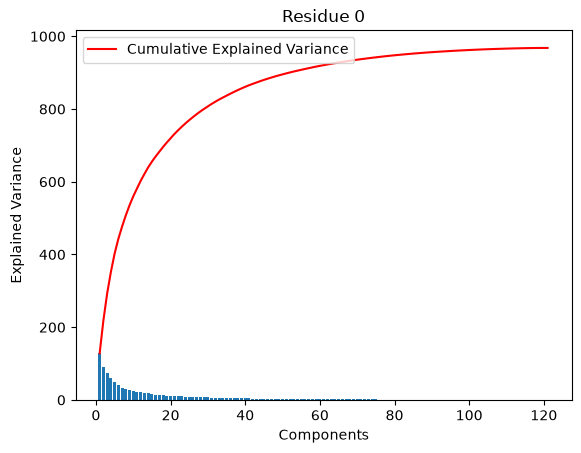

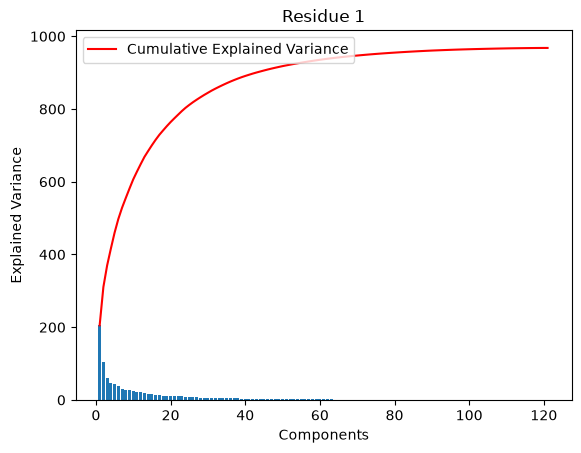

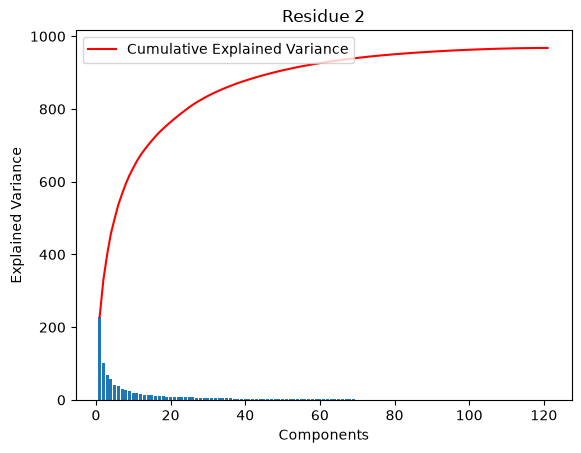

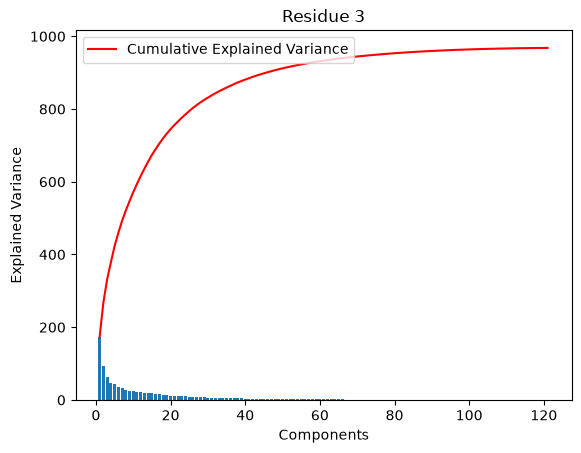

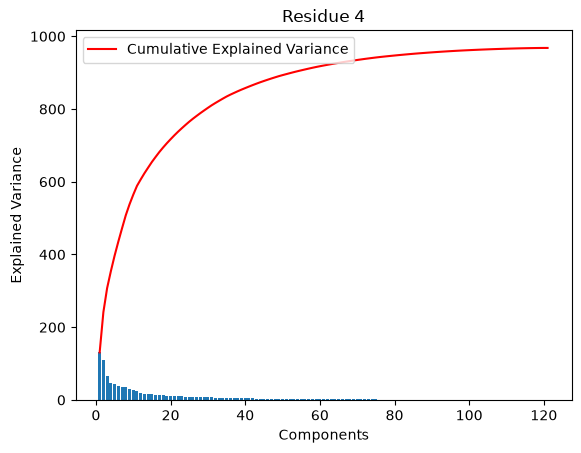

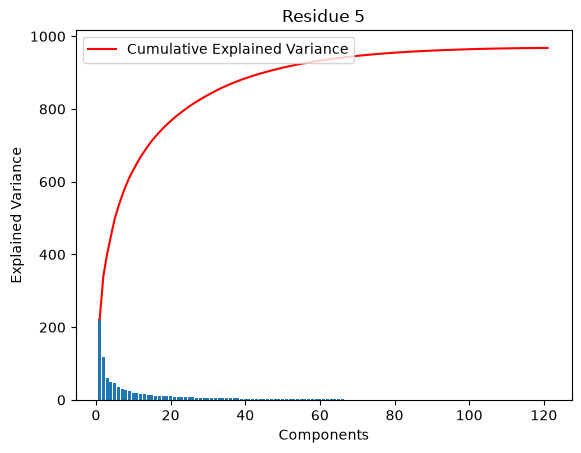

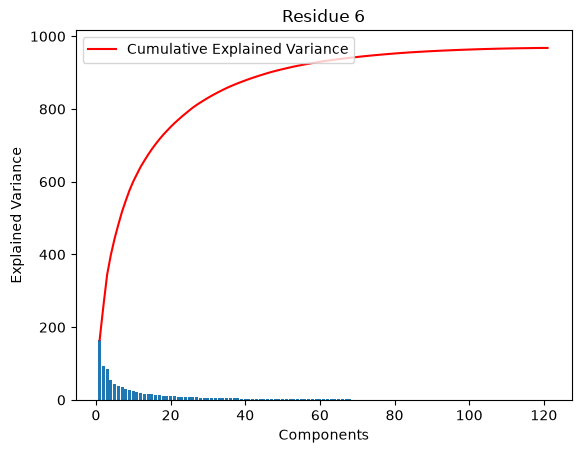

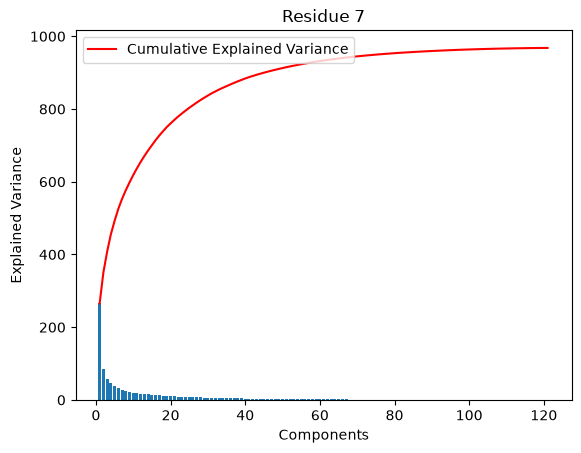

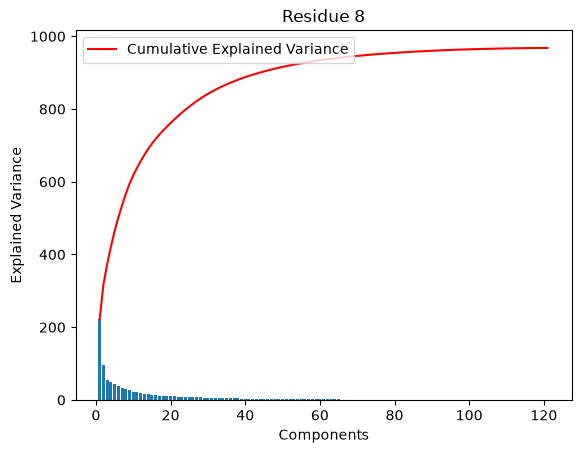

In [43]:
for i in range(0, 9):
    residue_embed = embed_np[:, i, :]

    residue_embed_scaled = scaleStandard.fit_transform(residue_embed)

    reside_embed_pca1 = pca1.fit_transform(residue_embed_scaled)

    plt.figure()
    plt.title("Residue " + str(i))
    plt.bar(range(1, len(pca1.explained_variance_)+1), pca1.explained_variance_)
    plt.ylabel('Explained Variance')
    plt.xlabel('Components')
    plt.plot(range(1,len(pca1.explained_variance_)+1),
             np.cumsum(pca1.explained_variance_),
             c='red',
             label='Cumulative Explained Variance')
    plt.legend(loc = 'upper left')

    # plt.figure()
    # plt.title("Residue " + str(i))
    # plt.plot(pca1.explained_variance_ratio_)
    # plt.xlabel('number of components')
    # plt.ylabel('cumulative explained variance')


plt.show()

In [ ]:
# 0.95 -> 55-60

# 0.91 -> around 40

pca2 = PCA(0.91)


for i in range(0, 9):

    residue_embed = embed_np[:, i, :]

    residue_embed_scaled = scaleStandard.fit_transform(residue_embed)

    residue_embed_pca2 = pca2.fit_transform(residue_embed_scaled)

    print(residue_embed_pca2.shape)





(121, 46)
(121, 38)
(121, 41)
(121, 40)
(121, 47)
(121, 40)
(121, 41)
(121, 40)
(121, 39)


In [ ]:
# Print entire dataset!

# print(len(df))
# with pd.option_context('display.max_rows', None, 'display.max_columns', None):
#     display(df) 

121


,taxid,virus_name,sDBM_pos,sDBM,sDBM_sim_gap,ori_seq,ori_align_score,iteration_name,rep_amino_acid_seq
0,59817,Faba bean necrotic yellows virus,"(63, 71)",GAHFEKRRG,33.0,TAGTATTAC,138.5,FBNYY_iter1_V_A,MARQVICWCFTLNNPLSPLSLHDSMKYLVYQTEQGEAGNIHFQGYI...
1,262588,Cardamom bushy dwarf virus,"(63, 71)",GAHLEKRKG,33.1,TATTATTAC,138.2,FBNYY_iter1_V_A,MARYVVCWMFTINNPSSLPVMRDEIKYMVYQVERGQEGTRHVQGYV...
4,2169722,Banana bunchy top alphasatellite 2,"(70, 78)",RAHWEKARG,40.3,TAGTATTAC,138.5,FBNYY_iter1_V_A,MSASRWTFTLHYSDATERGKFLATLKEEDVHYAVVGDETAPNTGRK...
6,1685737,Lake Sarah-associated circular virus-11,"(74, 82)",RAHFECAKG,40.2,CAGTATTAC,137.7,FBNYY_iter1_V_A,MAPRGNAAKRWTFTINNWTLADYDKVLEFTTKFEPVFLICGKERGE...
7,2293298,Pimoid spider associated circular virus 2,"(66, 74)",SAHWERTKG,36.8,TAGTATTAC,138.5,FBNYY_iter1_V_A,MSCKNWCFTWNNPDLGYEALLELLSSKSSYCIFQKEQGANGTVHFQ...
8,3429808,Hudisavirus jaqis,"(73, 81)",RAHWEKTRG,37.0,GAGTATTAC,136.3,FBNYY_iter1_V_A,MSAQEGAAKRWCFTINNPTDDDKFWENSEQQEHLEYLIIQEEIGEN...
9,2800901,Marmot associated feces virus 6,"(68, 76)",KIHWEPRKG,29.4,AATTATTAC,137.5,FBNYY_iter1_V_A,MSRNRNWVFTFNNPYDIEIQMLDKILTSQADYAIYGEEVGENGTPH...
10,1234878,Dragonfly cyclicusvirus,"(67, 75)",RYHIEMRRG,37.5,TAGTATTAC,138.5,FBNYY_iter1_V_A,MGSPAIGWCFTLNNYTEIDEQVLQALDVKYLVYGHEVGEGGTPHLQ...
11,2676049,Penguin circovirus,"(73, 81)",RAHWEKARG,42.2,TAGTATTAC,138.5,FBNYY_iter1_V_A,MAPVRAAGARRWCLTLNNPTDEEVQAAKRLEPNTYHYAIIGREVGE...
12,2293292,Golden silk orbweaver associated circular virus 1,"(64, 72)",GAHFERARG,39.7,CAGTATTAC,137.7,FBNYY_iter1_V_A,MSKCKRWLFTSYNVVSEPFYDEKIHEYLCFGRETCPSTNRRHLQGY...
